# NASA C-MAPSS RUL Prediction

## Three Follow-up Experiments

This notebook extends the baseline in `02_CMAPSS_Model_Training.ipynb`. It does not change that notebook or refit the baseline.

The research question is how Linear Regression, SVR, Random Forest, and XGBoost compare across FD001–FD004, where the datasets differ in operating conditions and fault modes.

Ramasso and Saxena (2014) describe three families of C-MAPSS methods. The baseline belongs to the first family: one cycle of sensor readings is mapped directly to remaining useful life. This notebook tests three changes suggested by that review:

1. Remove the effect of the operating regime from the sensors before predicting.
2. Compress the adjusted sensors into one health index, then predict remaining life from that index.
3. Match the health-index history of a test engine to complete training histories.

The engine split, random seed, RUL cap, model settings, and official test protocol stay the same as the baseline. Official test labels are not used to choose any setting.


## Imports and Configuration

The shared functions are defined in the next cell. They load the saved engine split, fit every transformation on the training engines only, and score the official test engines once.

A perfect RMSE or MAE is 0. Both measure error in cycles. The NASA score is also an error penalty, and a perfect model scores 0. Lower is better for all three.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass


In [2]:
"""Three follow-up C-MAPSS experiments.

Operating-condition normalization, a linear health index, and
health-index trajectory matching. The engine split, RUL cap, model
settings, and official test protocol match notebook 02.
"""

from __future__ import annotations

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

RANDOM_STATE = 42
RUL_CAP = 125
HEALTHY_RUL = 125
LATE_RUL = 15
MIN_HEALTHY_ROWS = 30
STD_FLOOR = 1e-6
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
MODEL_NAMES = ["Linear Regression", "SVR", "Random Forest", "XGBoost"]
N_REGIMES = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}
OP_COLS = ["op_setting_1", "op_setting_2", "op_setting_3"]
RAW_COLUMNS = ["unit", "cycle", *OP_COLS] + [f"sensor_{i}" for i in range(1, 22)]


def project_paths():
    cwd = Path.cwd()
    if (cwd / "processed_data" / "retained_features.json").exists():
        root = cwd
    elif (cwd.parent / "processed_data" / "retained_features.json").exists():
        root = cwd.parent
    else:
        raise FileNotFoundError("Could not find processed_data/retained_features.json")
    figures = root / "results" / "advanced_figures"
    figures.mkdir(parents=True, exist_ok=True)
    return root, root / "processed_data", root / "data", root / "results", figures


def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def nasa_score(y_true, y_pred):
    """NASA/PHM score. d = predicted RUL - true RUL. Lower is better."""
    d = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    with np.errstate(over="ignore"):
        terms = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    total = float(np.sum(terms))
    if not np.isfinite(total):
        return float("inf")
    return total


def evaluate(y_true, y_pred):
    return {
        "RMSE": rmse(y_true, y_pred),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "NASA": nasa_score(y_true, y_pred),
    }


def load_resources():
    root, processed, data, results, figures = project_paths()
    retained = json.loads((processed / "retained_features.json").read_text(encoding="utf-8"))
    selected = json.loads((results / "selected_hyperparameters.json").read_text(encoding="utf-8"))
    baseline = pd.read_csv(results / "model_comparison.csv")
    return {
        "root": root,
        "processed": processed,
        "data": data,
        "results": results,
        "figures": figures,
        "retained": retained,
        "selected": selected,
        "baseline": baseline,
    }


def sensor_columns(retained, subset):
    return [column for column in retained[subset] if column.startswith("sensor_")]


def setting_columns(retained, subset):
    return [column for column in retained[subset] if column.startswith("op_setting")]


def load_split(processed, subset):
    train_df = pd.read_csv(processed / f"train_{subset}_split.csv")
    val_df = pd.read_csv(processed / f"val_{subset}_split.csv")
    overlap = set(train_df["unit"]).intersection(val_df["unit"])
    if overlap:
        raise ValueError(f"{subset} has engines in both splits: {sorted(overlap)[:5]}")
    return train_df, val_df


def load_test_trajectories(data, processed, subset):
    """Full test trajectories. Official RUL is attached only to the last cycle."""
    test_df = pd.read_csv(
        data / f"test_{subset}.txt",
        sep=r"\s+",
        header=None,
        names=RAW_COLUMNS,
    )
    if subset == "FD001":
        rul_path = processed / "y_test_FD001_full.csv"
    else:
        rul_path = processed / f"y_test_{subset}.csv"
    official_rul = pd.read_csv(rul_path)["RUL"].to_numpy()
    last = (
        test_df.sort_values(["unit", "cycle"])
        .groupby("unit", sort=True)
        .tail(1)
        .sort_values("unit")
        .reset_index(drop=True)
    )
    expected_units = list(range(1, len(official_rul) + 1))
    if last["unit"].tolist() != expected_units:
        raise ValueError(f"{subset} test units are not 1..N in order")
    test_df = test_df.copy()
    test_df["RUL"] = np.nan
    last_index = (
        test_df.sort_values(["unit", "cycle"])
        .groupby("unit", sort=True)
        .tail(1)
        .sort_values("unit")
        .index
    )
    test_df.loc[last_index, "RUL"] = official_rul
    return test_df


def fit_regime_model(train_df, n_regimes):
    """Cluster operating settings on the training split only."""
    scaler = StandardScaler()
    scaled = scaler.fit_transform(train_df[OP_COLS])
    if n_regimes == 1:
        return {"scaler": scaler, "kmeans": None, "n_regimes": 1}
    model = KMeans(n_clusters=n_regimes, random_state=RANDOM_STATE, n_init=10)
    model.fit(scaled)
    return {"scaler": scaler, "kmeans": model, "n_regimes": n_regimes}


def regime_centers(regime_model):
    if regime_model["kmeans"] is None:
        return None
    return regime_model["scaler"].inverse_transform(regime_model["kmeans"].cluster_centers_)


def assign_regimes(df, regime_model):
    out = df.copy()
    scaled = regime_model["scaler"].transform(out[OP_COLS])
    if regime_model["kmeans"] is None:
        out["regime"] = 0
    else:
        out["regime"] = regime_model["kmeans"].predict(scaled)
    return out


def fit_healthy_reference(train_df, sensors):
    """Mean and std of each sensor inside each regime, using healthy cycles.

    Healthy means uncapped RUL is still at or above the 125-cycle knee
    already used by the baseline. A regime with too few such cycles falls
    back to all of its training cycles.
    """
    reference = {}
    for regime, group in train_df.groupby("regime"):
        healthy = group[group["RUL"] >= HEALTHY_RUL]
        used_fallback = False
        if len(healthy) < MIN_HEALTHY_ROWS:
            healthy = group
            used_fallback = True
        stds = healthy[sensors].std(ddof=0)
        reference[int(regime)] = {
            "mean": healthy[sensors].mean(),
            "std": stds,
            "n_healthy": int(len(healthy)),
            "n_regime": int(len(group)),
            "used_fallback": used_fallback,
        }
    return reference


def apply_normalization(df, sensors, reference):
    out = df.copy()
    for sensor in sensors:
        out[f"norm_{sensor}"] = np.nan
    for regime, index in out.groupby("regime").groups.items():
        stats = reference[int(regime)]
        values = out.loc[index, sensors]
        std = stats["std"].astype(float).copy()
        std[std < STD_FLOOR] = np.nan
        adjusted = (values - stats["mean"]) / std
        adjusted = adjusted.fillna(0.0)
        for sensor in sensors:
            out.loc[index, f"norm_{sensor}"] = adjusted[sensor].to_numpy()
    if out[[f"norm_{sensor}" for sensor in sensors]].isna().any().any():
        missing = sorted(set(out["regime"]) - set(reference))
        raise ValueError(f"Regimes missing a training reference: {missing}")
    return out


def model_matrix(df, sensors, settings):
    columns = [f"norm_{sensor}" for sensor in sensors] + list(settings)
    return df[columns]


def make_model(model_name, params):
    if model_name == "Linear Regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LinearRegression()),
        ])
    if model_name == "SVR":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", SVR(cache_size=1000, **params)),
        ])
    if model_name == "Random Forest":
        kwargs = dict(params)
        if kwargs.get("max_depth") is None:
            kwargs.pop("max_depth", None)
        return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **kwargs)
    if model_name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            tree_method="hist",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )
    raise ValueError(model_name)


def fit_and_score(model_name, params, X_train, y_train, X_val, y_val, X_test, y_test):
    model = make_model(model_name, params)
    started = time.perf_counter()
    model.fit(X_train, y_train)
    elapsed = time.perf_counter() - started
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)
    row = {
        "model": model_name,
        "fit_seconds": elapsed,
        "test_pred_min": float(np.min(test_pred)),
        "test_pred_max": float(np.max(test_pred)),
    }
    row.update({f"val_{key}": value for key, value in evaluate(y_val, val_pred).items()})
    row.update({f"test_{key}": value for key, value in evaluate(y_test, test_pred).items()})
    capped_test = np.minimum(y_test, RUL_CAP)
    row.update({
        f"test_capped_{key}": value
        for key, value in evaluate(capped_test, test_pred).items()
    })
    return row


def prepare_subset(bundle, subset):
    train_df, val_df = load_split(bundle["processed"], subset)
    test_df = load_test_trajectories(bundle["data"], bundle["processed"], subset)
    sensors = sensor_columns(bundle["retained"], subset)
    settings = setting_columns(bundle["retained"], subset)
    regime_model = fit_regime_model(train_df, N_REGIMES[subset])
    train_df = assign_regimes(train_df, regime_model)
    val_df = assign_regimes(val_df, regime_model)
    test_df = assign_regimes(test_df, regime_model)
    reference = fit_healthy_reference(train_df, sensors)
    train_df = apply_normalization(train_df, sensors, reference)
    val_df = apply_normalization(val_df, sensors, reference)
    test_df = apply_normalization(test_df, sensors, reference)
    return {
        "subset": subset,
        "train_df": train_df,
        "val_df": val_df,
        "test_df": test_df,
        "sensors": sensors,
        "settings": settings,
        "reference": reference,
        "regime_model": regime_model,
        "n_regimes": N_REGIMES[subset],
    }


def supervised_frames(prepared):
    sensors = prepared["sensors"]
    settings = prepared["settings"]
    train_df = prepared["train_df"]
    val_df = prepared["val_df"]
    test_last = (
        prepared["test_df"].sort_values(["unit", "cycle"])
        .groupby("unit", sort=True)
        .tail(1)
        .sort_values("unit")
    )
    if test_last["RUL"].isna().any():
        raise ValueError(f"{prepared['subset']} is missing official test RUL")
    return {
        "X_train": model_matrix(train_df, sensors, settings),
        "y_train": np.minimum(train_df["RUL"].to_numpy(), RUL_CAP),
        "X_val": model_matrix(val_df, sensors, settings),
        "y_val": np.minimum(val_df["RUL"].to_numpy(), RUL_CAP),
        "X_test": model_matrix(test_last, sensors, settings),
        "y_test": test_last["RUL"].to_numpy(),
    }


def run_health_experiment(bundle, prepared, models):
    """Predict capped RUL from the health index alone."""
    enriched, frames = health_frames(prepared)
    rows = []
    subset = prepared["subset"]
    print(
        f"  health index | {subset} | early anchors {frames['n_early']} | "
        f"late anchors {frames['n_late']}",
        flush=True,
    )
    for model_name in models:
        params = bundle["selected"][subset][model_name]
        print(f"  Health index | {subset} | {model_name}", flush=True)
        row = fit_and_score(
            model_name,
            params,
            frames["X_train"],
            frames["y_train"],
            frames["X_val"],
            frames["y_val"],
            frames["X_test"],
            frames["y_test"],
        )
        row.update({"dataset": subset, "experiment": "Health index"})
        print(
            f"    val RMSE {row['val_RMSE']:.2f} | test RMSE {row['test_RMSE']:.2f} | "
            f"{row['fit_seconds']:.1f}s",
            flush=True,
        )
        rows.append(row)
    return enriched, rows


def run_supervised_experiment(bundle, prepared, experiment, models):
    frames = supervised_frames(prepared)
    rows = []
    subset = prepared["subset"]
    for model_name in models:
        params = bundle["selected"][subset][model_name]
        print(f"  {experiment} | {subset} | {model_name}", flush=True)
        row = fit_and_score(
            model_name,
            params,
            frames["X_train"],
            frames["y_train"],
            frames["X_val"],
            frames["y_val"],
            frames["X_test"],
            frames["y_test"],
        )
        row.update({"dataset": subset, "experiment": experiment})
        print(
            f"    val RMSE {row['val_RMSE']:.2f} | test RMSE {row['test_RMSE']:.2f} | "
            f"{row['fit_seconds']:.1f}s",
            flush=True,
        )
        rows.append(row)
    return rows


def fit_health_index(train_df, sensors):
    """Linear health index fit on training anchors only.

    Cycles at or above the 125-cycle knee are the healthy reference (1).
    Cycles with 15 or fewer cycles left are the failed reference (0).
    This follows the piecewise-RUL knee already used in the baseline.
    It is a linear implementation choice, not a reproduction of a
    published health-index formula.
    """
    early = train_df["RUL"] >= HEALTHY_RUL
    late = train_df["RUL"] <= LATE_RUL
    anchors = train_df.loc[early | late].copy()
    if anchors.empty:
        raise ValueError("No health-index anchor cycles were found")
    target = np.where(anchors["RUL"].to_numpy() <= LATE_RUL, 0.0, 1.0)
    features = anchors[[f"norm_{sensor}" for sensor in sensors]]
    model = LinearRegression()
    model.fit(features, target)
    return model, int(early.sum()), int(late.sum())


def add_health_index(df, model, sensors):
    features = df[[f"norm_{sensor}" for sensor in sensors]]
    out = df.copy()
    out["health_index"] = np.clip(model.predict(features), 0.0, 1.0)
    return out


def health_frames(prepared):
    model, n_early, n_late = fit_health_index(prepared["train_df"], prepared["sensors"])
    train_df = add_health_index(prepared["train_df"], model, prepared["sensors"])
    val_df = add_health_index(prepared["val_df"], model, prepared["sensors"])
    test_df = add_health_index(prepared["test_df"], model, prepared["sensors"])
    test_last = (
        test_df.sort_values(["unit", "cycle"])
        .groupby("unit", sort=True)
        .tail(1)
        .sort_values("unit")
    )
    prepared = dict(prepared)
    prepared.update({"train_df": train_df, "val_df": val_df, "test_df": test_df, "hi_model": model})
    frames = {
        "X_train": train_df[["health_index"]],
        "y_train": np.minimum(train_df["RUL"].to_numpy(), RUL_CAP),
        "X_val": val_df[["health_index"]],
        "y_val": np.minimum(val_df["RUL"].to_numpy(), RUL_CAP),
        "X_test": test_last[["health_index"]],
        "y_test": test_last["RUL"].to_numpy(),
        "n_early": n_early,
        "n_late": n_late,
    }
    return prepared, frames


def engine_library(train_df):
    library = []
    for unit, group in train_df.groupby("unit", sort=True):
        ordered = group.sort_values("cycle")
        library.append({
            "unit": int(unit),
            "health_index": ordered["health_index"].to_numpy(dtype=float),
            "rul": ordered["RUL"].to_numpy(dtype=float),
        })
    return library


def best_window_match(query, series, window):
    width = min(window, len(query), len(series["health_index"]))
    if width < 5:
        return None
    query_tail = query[-width:]
    windows = np.lib.stride_tricks.sliding_window_view(series["health_index"], width)
    distances = np.sqrt(np.mean((windows - query_tail) ** 2, axis=1))
    position = int(np.argmin(distances))
    end = position + width - 1
    return (
        float(distances[position]),
        float(series["rul"][end]),
        int(series["unit"]),
        width,
        position,
    )


def match_rul(query, library, window, neighbors):
    found = []
    for series in library:
        matched = best_window_match(query, series, window)
        if matched is not None:
            found.append(matched)
    if not found:
        raise ValueError("No training trajectory was long enough to match")
    found.sort(key=lambda item: item[0])
    chosen = found[:neighbors]
    distances = np.array([item[0] for item in chosen], dtype=float)
    ruls = np.array([item[1] for item in chosen], dtype=float)
    weights = 1.0 / (distances + 1e-6)
    prediction = float(np.sum(weights * ruls) / np.sum(weights))
    return prediction, chosen


def similarity_validation_rows(val_df, library, window, neighbors):
    y_true = []
    y_pred = []
    fractions = (0.50, 0.70, 0.85)
    for _, group in val_df.groupby("unit", sort=True):
        ordered = group.sort_values("cycle")
        health = ordered["health_index"].to_numpy(dtype=float)
        rul = ordered["RUL"].to_numpy(dtype=float)
        length = len(ordered)
        for fraction in fractions:
            end = min(length - 1, max(4, int(round(fraction * length)) - 1))
            prediction, _ = match_rul(health[: end + 1], library, window, neighbors)
            y_true.append(min(float(rul[end]), RUL_CAP))
            y_pred.append(prediction)
    return np.array(y_true), np.array(y_pred)


def run_similarity(prepared, windows=(20, 40), neighbors=(5, 10)):
    library = engine_library(prepared["train_df"])
    subset = prepared["subset"]
    best = None
    search_rows = []
    for window in windows:
        for neighbor_count in neighbors:
            y_true, y_pred = similarity_validation_rows(
                prepared["val_df"], library, window, neighbor_count
            )
            scores = evaluate(y_true, y_pred)
            row = {
                "dataset": subset,
                "window": window,
                "neighbors": neighbor_count,
                **{f"val_{key}": value for key, value in scores.items()},
            }
            search_rows.append(row)
            print(
                f"  similarity | {subset} | window {window} | k {neighbor_count} | "
                f"val RMSE {scores['RMSE']:.2f}",
                flush=True,
            )
            if best is None or scores["RMSE"] < best["scores"]["RMSE"]:
                best = {
                    "window": window,
                    "neighbors": neighbor_count,
                    "scores": scores,
                }
    test_true = []
    test_pred = []
    examples = []
    ordered_test = prepared["test_df"].sort_values(["unit", "cycle"])
    for unit, group in ordered_test.groupby("unit", sort=True):
        health = group["health_index"].to_numpy(dtype=float)
        official = group["RUL"].dropna()
        if len(official) != 1:
            raise ValueError(f"{subset} unit {unit} does not have one official RUL")
        prediction, chosen = match_rul(
            health, library, best["window"], best["neighbors"]
        )
        test_true.append(float(official.iloc[0]))
        test_pred.append(prediction)
        if len(examples) < 1:
            distance, matched_rul, match_unit, width, position = chosen[0]
            matched_series = next(item for item in library if item["unit"] == match_unit)
            examples.append({
                "unit": int(unit),
                "query_tail": health[-width:],
                "match_hi": matched_series["health_index"][position: position + width],
                "match_unit": match_unit,
                "distance": distance,
                "matched_rul": matched_rul,
                "prediction": prediction,
                "actual": float(official.iloc[0]),
            })
    test_true = np.array(test_true)
    test_pred = np.array(test_pred)
    test_scores = evaluate(test_true, test_pred)
    capped_scores = evaluate(np.minimum(test_true, RUL_CAP), test_pred)
    result = {
        "dataset": subset,
        "experiment": "History matching",
        "model": "Similarity",
        "window": best["window"],
        "neighbors": best["neighbors"],
        "val_RMSE": best["scores"]["RMSE"],
        "val_MAE": best["scores"]["MAE"],
        "val_NASA": best["scores"]["NASA"],
        "test_RMSE": test_scores["RMSE"],
        "test_MAE": test_scores["MAE"],
        "test_NASA": test_scores["NASA"],
        "test_capped_RMSE": capped_scores["RMSE"],
        "test_capped_MAE": capped_scores["MAE"],
        "test_capped_NASA": capped_scores["NASA"],
        "test_pred_min": float(np.min(test_pred)),
        "test_pred_max": float(np.max(test_pred)),
        "fit_seconds": np.nan,
    }
    print(
        f"  selected similarity | {subset} | window {best['window']} | "
        f"k {best['neighbors']} | test RMSE {test_scores['RMSE']:.2f}",
        flush=True,
    )
    return result, search_rows, examples, library


def run_all(models=None, subsets=None):
    """Run all three experiments and checkpoint results after each dataset."""
    bundle = load_resources()
    models = list(models or MODEL_NAMES)
    subsets = list(subsets or SUBSETS)
    log_path = bundle["results"] / "advanced_training_log.txt"
    log_path.write_text("", encoding="utf-8")
    import builtins
    original_print = builtins.print

    def log(message):
        original_print(message, flush=True)
        with log_path.open("a", encoding="utf-8") as handle:
            handle.write(str(message) + "\n")

    def tee_print(*args, **kwargs):
        kwargs.setdefault("flush", True)
        original_print(*args, **kwargs)
        text = " ".join(str(arg) for arg in args)
        with log_path.open("a", encoding="utf-8") as handle:
            handle.write(text + "\n")

    builtins.print = tee_print
    try:
        norm_rows = []
        health_rows = []
        sim_rows = []
        sim_search = []
        prepared_by_subset = {}
        examples = {}
        for subset in subsets:
            log("\n" + "=" * 60)
            log(subset)
            log("=" * 60)
            prepared = prepare_subset(bundle, subset)
            norm_rows.extend(run_supervised_experiment(
                bundle, prepared, "Normalization", models
            ))
            enriched, health_part = run_health_experiment(bundle, prepared, models)
            health_rows.extend(health_part)
            similarity, search_part, example, _library = run_similarity(enriched)
            sim_rows.append(similarity)
            sim_search.extend(search_part)
            prepared_by_subset[subset] = enriched
            examples[subset] = example
            _write_checkpoints(bundle["results"], norm_rows, health_rows, sim_rows, sim_search)
            log(f"{subset} checkpoint saved")
    finally:
        builtins.print = original_print
    return {
        "bundle": bundle,
        "norm_rows": norm_rows,
        "health_rows": health_rows,
        "sim_rows": sim_rows,
        "sim_search": sim_search,
        "prepared": prepared_by_subset,
        "examples": examples,
    }


def _write_checkpoints(results_dir, norm_rows, health_rows, sim_rows, sim_search):
    pd.DataFrame(norm_rows).to_csv(results_dir / "advanced_normalization.csv", index=False)
    pd.DataFrame(health_rows).to_csv(results_dir / "advanced_health_index.csv", index=False)
    pd.DataFrame(sim_rows).to_csv(results_dir / "advanced_similarity.csv", index=False)
    pd.DataFrame(sim_search).to_csv(results_dir / "advanced_similarity_search.csv", index=False)


## Dataset Loading and Baseline Review

The baseline files are the engine-wise 80/20 split already saved from notebook 02, with random seed 42. Validation engines and training engines do not overlap. FD001 test features come from `X_test_FD001_full.csv` indirectly: this notebook reloads the full test trajectories and attaches the same official RUL file.

One methodological limit of the baseline is recorded here rather than changed. Its validation NASA score adds a penalty for every cycle, while the official test NASA score adds a penalty once per engine. The comparison below uses the official test scores from `results/model_comparison.csv`.


In [3]:
bundle = load_resources()
baseline = bundle["baseline"].copy()
print("Baseline rows:", len(baseline))
print("Datasets:", baseline["dataset"].unique().tolist())
display(baseline[[
    "dataset", "model", "test_RMSE", "test_MAE", "test_NASA"
]].round(2))

for subset in SUBSETS:
    train_df, val_df = load_split(bundle["processed"], subset)
    print(
        f"{subset}: train engines {train_df['unit'].nunique()}, "
        f"validation engines {val_df['unit'].nunique()}, "
        f"overlap {len(set(train_df['unit']) & set(val_df['unit']))}"
    )


Baseline rows: 16
Datasets: ['FD001', 'FD002', 'FD003', 'FD004']


,dataset,model,test_RMSE,test_MAE,test_NASA
0,FD001,Linear Regression,21.88,17.62,1307.55
1,FD001,SVR,18.47,13.38,1018.41
2,FD001,Random Forest,18.03,12.96,894.79
3,FD001,XGBoost,18.15,12.71,1024.02
4,FD002,Linear Regression,32.55,24.36,18581.85
5,FD002,SVR,31.80,23.25,22150.26
6,FD002,Random Forest,29.28,20.81,12227.72
7,FD002,XGBoost,28.87,20.43,10796.91
8,FD003,Linear Regression,22.36,18.03,1656.24
9,FD003,SVR,21.00,16.08,1777.60


FD001: train engines 80, validation engines 20, overlap 0
FD002: train engines 208, validation engines 52, overlap 0


FD003: train engines 80, validation engines 20, overlap 0

FD004: train engines 199, validation engines 50, overlap 0


## Shared Preparation Rules

- Training and validation labels are capped at 125 cycles, as in the baseline. The saved files still contain the original uncapped RUL.
- Official test RUL stays uncapped for the main score.
- K-Means uses the three operating settings. It is fit on the training split only. FD002 and FD004 use six regimes, the number built into those datasets (Ramasso & Saxena, 2014). FD001 and FD003 use one regime because they were simulated under one operating condition.
- A healthy cycle is a training cycle whose uncapped RUL is still at least 125. That is the same knee the baseline uses when it caps the target.
- Sensor adjustment is `(reading - healthy mean in that regime) / healthy standard deviation in that regime`. A standard deviation below `1e-6` is treated as no variation, and the adjusted value is set to 0.
- The four models keep the hyperparameters chosen in notebook 02. They are not tuned again. Retuning could be done on validation data, but it would mix a new representation with a new search.
- Model inputs for the normalization experiment are the adjusted sensors plus the operating settings the baseline already retained. The settings are not adjusted, because they define the regime.


## Experiment 1: Operating-Condition Normalization

On FD001, a change in a sensor usually means wear, because the engine is always flown the same way. On FD002 and FD004, the same sensor also jumps when the flight regime changes. Dividing by the healthy level inside each regime is meant to leave the wear signal and take out the regime jump.

The same four models are then trained on the adjusted data.


## Experiment 2: Health-Index Construction

The health index is a linear score learned only from training anchors. Cycles with at least 125 cycles left are coded as 1. Cycles with 15 or fewer cycles left are coded as 0. A linear regression maps the adjusted sensors to that 0/1 target, and the score is clipped to the range 0 to 1.

This is not a claim that the score equals remaining life. Remaining life is predicted by the same four models, using the health index as their only input. A single linear index is a limitation on FD003 and FD004, which contain two fault modes and may wear in more than one direction.


## Experiment 3: Engine-History Matching

Each training engine keeps its health-index sequence from the first cycle to failure. A test engine has only the cycles observed so far. The last 20 or 40 health-index values are slid along every training sequence. The distance is the root mean squared difference. The remaining life at the end of a matched training window is that training engine's true remaining life.

The five or ten closest training engines are averaged with weights `1 / (distance + 1e-6)`. The window length and the number of neighbors are chosen on censored prefixes of the validation engines (at 50%, 70%, and 85% of each validation life), scored against capped RUL. Those validation engines are run to failure, so their final cycle would have RUL 0 and would not resemble the official test. The official test labels are not used in this choice.

This is a simplified health-index similarity method in the spirit of category 3 in Ramasso and Saxena (2014). It is not a reproduction of a specific published matcher.


## Run the Three Experiments

Results are written to `results/` after each dataset. The baseline notebook is not retrained.


In [4]:
experiment = run_all()
print("Experiments finished.")
print("Normalization rows:", len(experiment["norm_rows"]))
print("Health-index rows:", len(experiment["health_rows"]))
print("Similarity rows:", len(experiment["sim_rows"]))


FD001


  Normalization | FD001 | Linear Regression


    val RMSE 20.41 | test RMSE 21.88 | 0.0s


  Normalization | FD001 | SVR


    val RMSE 17.19 | test RMSE 18.47 | 17.2s


  Normalization | FD001 | Random Forest


... (87 outputs left out)

  similarity | FD004 | window 40 | k 10 | val RMSE 37.02


  selected similarity | FD004 | window 40 | k 10 | test RMSE 36.86


FD004 checkpoint saved


Experiments finished.
Normalization rows: 16
Health-index rows: 16
Similarity rows: 4


## Comparison with the Baseline

Table A compares each model after operating-condition normalization with the same model in the baseline. A positive improvement means the error went down.

Table B uses one official-test result per approach. For the baseline, normalization, and health index, the model is the one with the lowest validation RMSE. History matching has one selected window setting. The official test was not used to make these choices.


In [5]:
from IPython.display import display

baseline = experiment["bundle"]["baseline"].copy()
norm_df = pd.DataFrame(experiment["norm_rows"])
health_df = pd.DataFrame(experiment["health_rows"])
sim_df = pd.DataFrame(experiment["sim_rows"])


def improvement(baseline_value, new_value):
    return (baseline_value - new_value) / baseline_value * 100.0


metric_map = {
    "RMSE": "test_RMSE",
    "MAE": "test_MAE",
    "NASA": "test_NASA",
}

table_a_parts = []
for metric, column in metric_map.items():
    merged = norm_df.merge(
        baseline[["dataset", "model", column]],
        on=["dataset", "model"],
        suffixes=("", "_baseline"),
    )
    part = pd.DataFrame({
        "Dataset": merged["dataset"],
        "Model": merged["model"],
        "Metric": metric,
        "Baseline": merged[f"{column}_baseline"],
        "Normalized": merged[column],
    })
    part["Improvement (%)"] = improvement(part["Baseline"], part["Normalized"])
    table_a_parts.append(part)

table_a = pd.concat(table_a_parts, ignore_index=True)
table_a = table_a.sort_values(["Metric", "Dataset", "Model"]).reset_index(drop=True)
display(table_a.round(2))
table_a.to_csv(experiment["bundle"]["results"] / "advanced_table_a.csv", index=False)


def selected_test_row(frame):
    ordered = frame.sort_values(["dataset", "val_RMSE"])
    return ordered.groupby("dataset", as_index=False).head(1)


base_best = selected_test_row(baseline)
norm_best = selected_test_row(norm_df)
health_best = selected_test_row(health_df)
sim_best = sim_df.sort_values("dataset")

rows = []
for subset in SUBSETS:
    base_row = base_best.loc[base_best["dataset"] == subset].iloc[0]
    norm_row = norm_best.loc[norm_best["dataset"] == subset].iloc[0]
    health_row = health_best.loc[health_best["dataset"] == subset].iloc[0]
    sim_row = sim_best.loc[sim_best["dataset"] == subset].iloc[0]
    for metric, column in metric_map.items():
        base_value = float(base_row[column])
        norm_value = float(norm_row[column])
        health_value = float(health_row[column])
        sim_value = float(sim_row[column])
        rows.append({
            "Dataset": subset,
            "Metric": metric,
            "Baseline model": base_row["model"],
            "Baseline": base_value,
            "Normalization model": norm_row["model"],
            "Normalization": norm_value,
            "Normalization improvement (%)": improvement(base_value, norm_value),
            "Health-index model": health_row["model"],
            "Health index": health_value,
            "Health-index improvement (%)": improvement(base_value, health_value),
            "History matching": sim_value,
            "History-matching improvement (%)": improvement(base_value, sim_value),
        })

table_b = pd.DataFrame(rows)
display(table_b.round(2))
table_b.to_csv(experiment["bundle"]["results"] / "advanced_table_b.csv", index=False)


,Dataset,Model,Metric,Baseline,Normalized,Improvement (%)
0,FD001,Linear Regression,MAE,17.62,17.62,-0.00
1,FD001,Random Forest,MAE,12.96,12.96,0.01
2,FD001,SVR,MAE,13.38,13.38,0.00
3,FD001,XGBoost,MAE,12.71,12.76,-0.43
4,FD002,Linear Regression,MAE,24.36,24.27,0.38
5,FD002,Random Forest,MAE,20.81,20.82,-0.05
6,FD002,SVR,MAE,23.25,20.33,12.55
7,FD002,XGBoost,MAE,20.43,20.74,-1.51
8,FD003,Linear Regression,MAE,18.03,18.03,-0.00
9,FD003,Random Forest,MAE,16.42,16.42,-0.04


,Dataset,Metric,Baseline model,Baseline,Normalization model,Normalization,Normalization improvement (%),Health-index model,Health index,Health-index improvement (%),History matching,History-matching improvement (%)
0,FD001,RMSE,XGBoost,18.15,XGBoost,18.07,0.46,XGBoost,19.98,-10.11,2.252000e+01,-24.10
1,FD001,MAE,XGBoost,12.71,XGBoost,12.76,-0.43,XGBoost,14.66,-15.36,1.664000e+01,-30.98
2,FD001,NASA,XGBoost,1024.02,XGBoost,973.63,4.92,XGBoost,1434.25,-40.06,2.646530e+03,-158.44
3,FD002,RMSE,XGBoost,28.87,XGBoost,29.42,-1.91,XGBoost,31.05,-7.54,2.710000e+01,6.15
4,FD002,MAE,XGBoost,20.43,XGBoost,20.74,-1.51,XGBoost,22.59,-10.57,1.943000e+01,4.89
5,FD002,NASA,XGBoost,10796.91,XGBoost,13338.48,-23.54,XGBoost,26256.67,-143.19,1.114384e+04,-3.21
6,FD003,RMSE,SVR,21.00,SVR,21.00,-0.00,XGBoost,23.55,-12.19,4.906000e+01,-133.68
7,FD003,MAE,SVR,16.08,SVR,16.08,0.00,XGBoost,18.29,-13.71,3.100000e+01,-92.76
8,FD003,NASA,SVR,1777.60,SVR,1777.60,-0.00,XGBoost,2563.77,-44.23,2.356610e+08,-13257143.03
9,FD004,RMSE,XGBoost,30.21,XGBoost,30.22,-0.05,XGBoost,33.77,-11.77,3.686000e+01,-22.02


## Results Visualization

The plots below show the regimes, the sensor adjustment, the health index, one history match, and the official-test errors. The bar charts use the selected result for each approach from Table B.


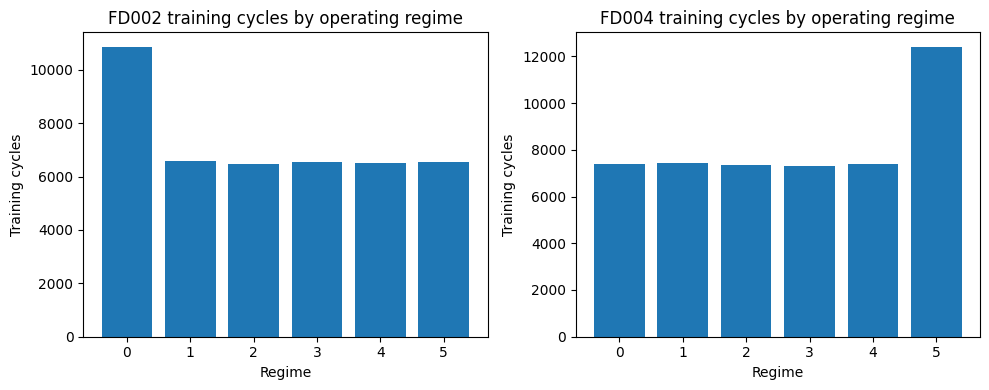

C:\Users\Eyasu\AppData\Local\Temp\ipykernel_15380\3676455648.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(raw_groups, labels=labels, showfliers=False)
C:\Users\Eyasu\AppData\Local\Temp\ipykernel_15380\3676455648.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(norm_groups, labels=labels, showfliers=False)


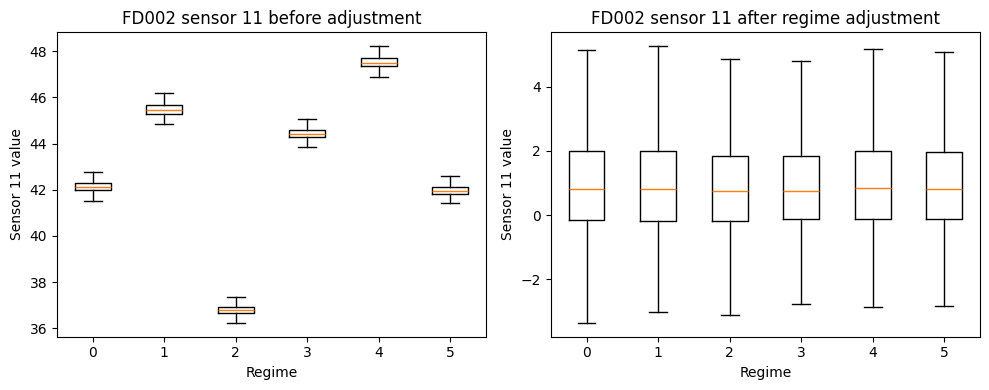

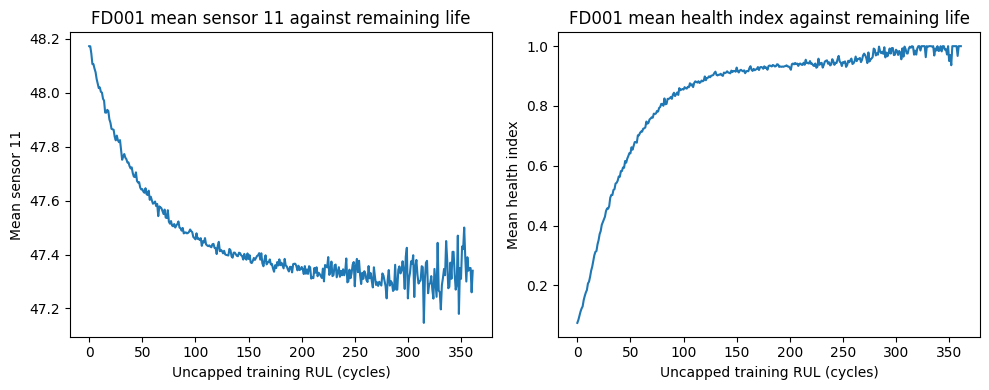

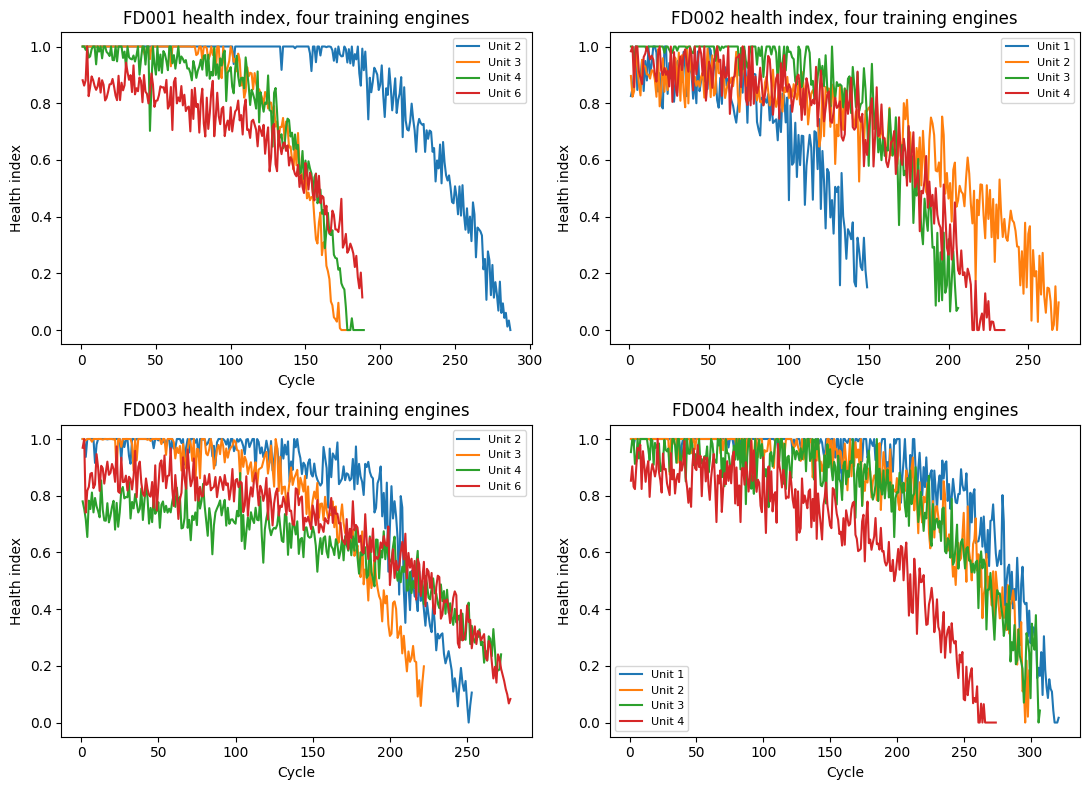

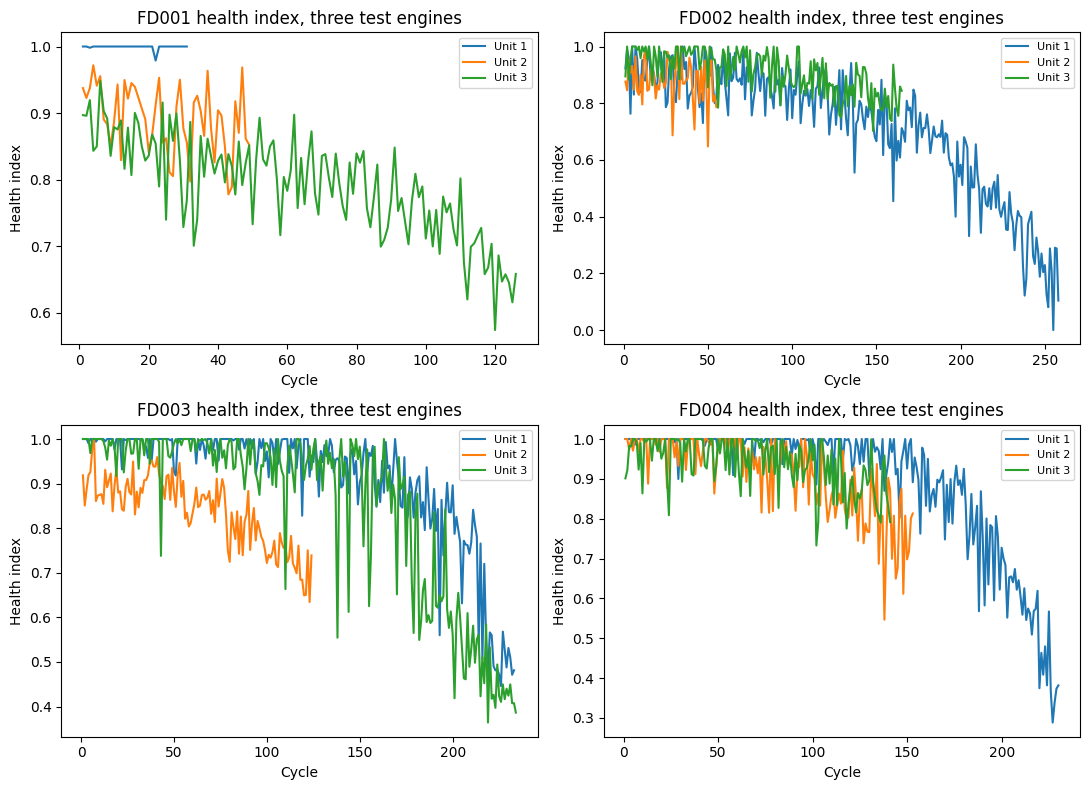

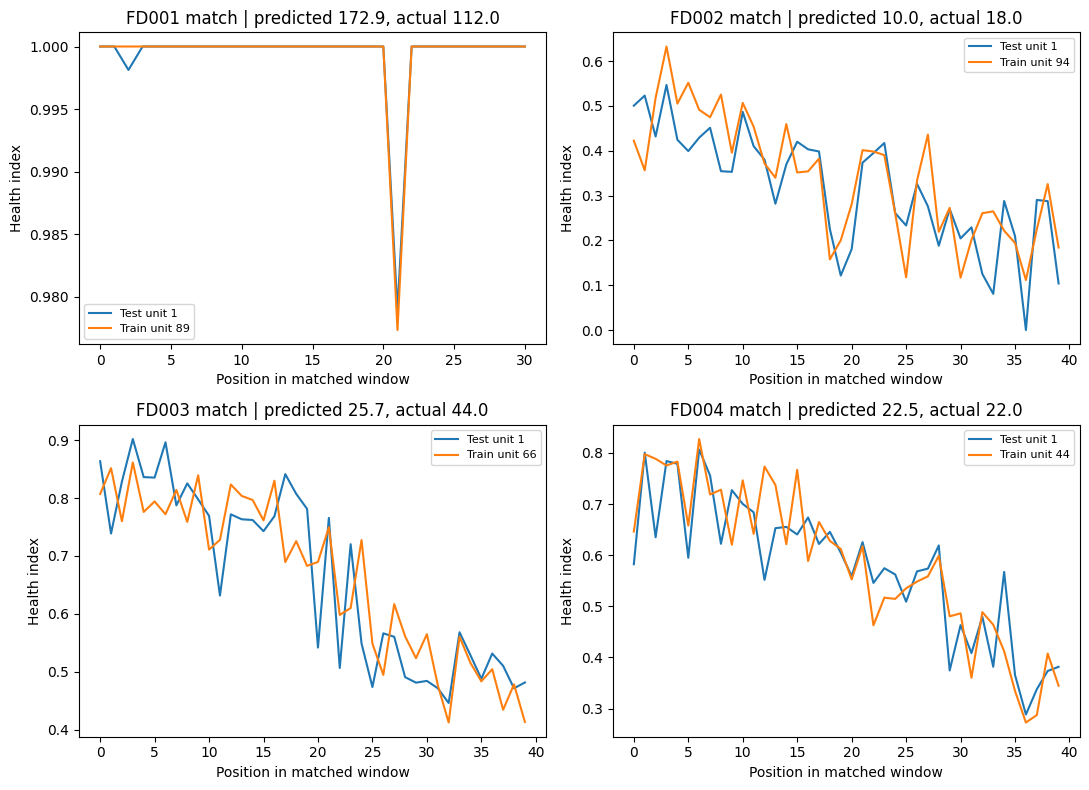

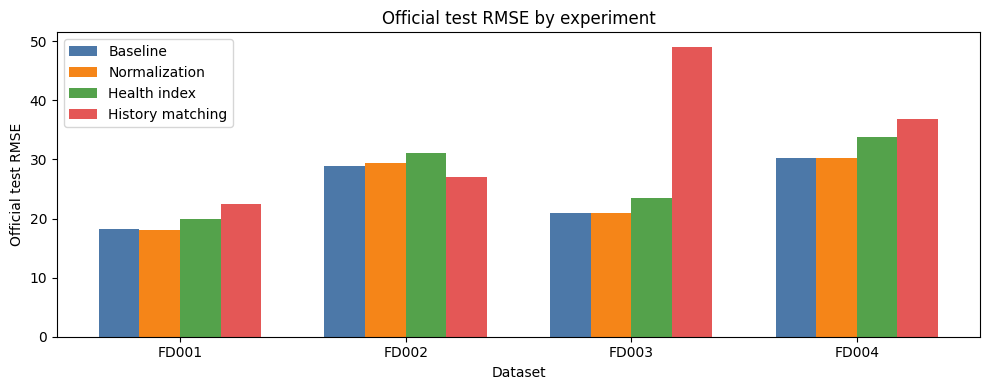

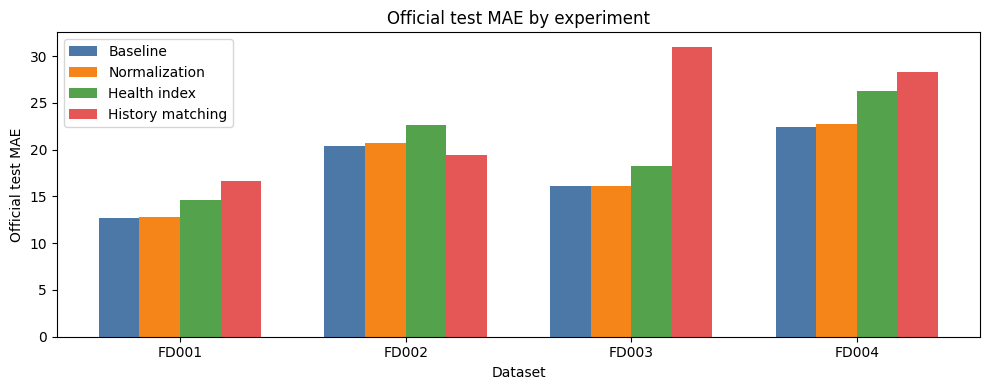

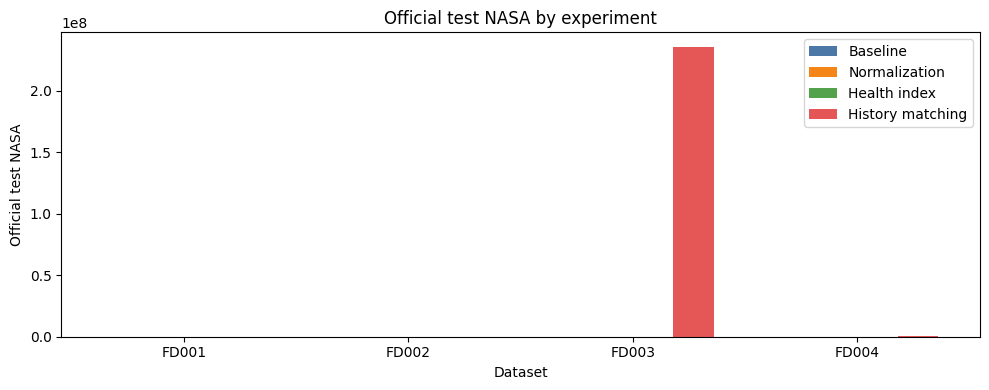

In [6]:
figures = experiment["bundle"]["figures"]
prepared = experiment["prepared"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for axis, subset in zip(axes, ["FD002", "FD004"]):
    counts = prepared[subset]["train_df"]["regime"].value_counts().sort_index()
    axis.bar(counts.index.astype(str), counts.values)
    axis.set_title(f"{subset} training cycles by operating regime")
    axis.set_xlabel("Regime")
    axis.set_ylabel("Training cycles")
fig.tight_layout()
fig.savefig(figures / "regime_counts.png", dpi=150)
plt.show()

fd002 = prepared["FD002"]["train_df"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
raw_groups = [group["sensor_11"].to_numpy() for _, group in fd002.groupby("regime")]
norm_groups = [group["norm_sensor_11"].to_numpy() for _, group in fd002.groupby("regime")]
labels = [str(regime) for regime, _group in fd002.groupby("regime")]
axes[0].boxplot(raw_groups, labels=labels, showfliers=False)
axes[1].boxplot(norm_groups, labels=labels, showfliers=False)
axes[0].set_title("FD002 sensor 11 before adjustment")
axes[1].set_title("FD002 sensor 11 after regime adjustment")
for axis in axes:
    axis.set_xlabel("Regime")
    axis.set_ylabel("Sensor 11 value")
fig.tight_layout()
fig.savefig(figures / "sensor11_before_after_fd002.png", dpi=150)
plt.show()

fd001 = prepared["FD001"]["train_df"]
trend = fd001.groupby("RUL")[["sensor_11", "health_index"]].mean().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(trend.index, trend["sensor_11"])
axes[0].set_title("FD001 mean sensor 11 against remaining life")
axes[0].set_xlabel("Uncapped training RUL (cycles)")
axes[0].set_ylabel("Mean sensor 11")
axes[1].plot(trend.index, trend["health_index"])
axes[1].set_title("FD001 mean health index against remaining life")
axes[1].set_xlabel("Uncapped training RUL (cycles)")
axes[1].set_ylabel("Mean health index")
fig.tight_layout()
fig.savefig(figures / "fd001_degradation_trend.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, subset in zip(axes.ravel(), SUBSETS):
    frame = prepared[subset]["train_df"]
    for unit in frame["unit"].drop_duplicates().head(4):
        group = frame.loc[frame["unit"] == unit].sort_values("cycle")
        axis.plot(group["cycle"], group["health_index"], label=f"Unit {int(unit)}")
    axis.set_title(f"{subset} health index, four training engines")
    axis.set_xlabel("Cycle")
    axis.set_ylabel("Health index")
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "health_index_training.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, subset in zip(axes.ravel(), SUBSETS):
    frame = prepared[subset]["test_df"]
    for unit in frame["unit"].drop_duplicates().head(3):
        group = frame.loc[frame["unit"] == unit].sort_values("cycle")
        axis.plot(group["cycle"], group["health_index"], label=f"Unit {int(unit)}")
    axis.set_title(f"{subset} health index, three test engines")
    axis.set_xlabel("Cycle")
    axis.set_ylabel("Health index")
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "health_index_test.png", dpi=150)
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for axis, subset in zip(axes.ravel(), SUBSETS):
    example = experiment["examples"][subset][0]
    axis.plot(example["query_tail"], label=f"Test unit {example['unit']}")
    axis.plot(example["match_hi"], label=f"Train unit {example['match_unit']}")
    axis.set_title(
        f"{subset} match | predicted {example['prediction']:.1f}, "
        f"actual {example['actual']:.1f}"
    )
    axis.set_xlabel("Position in matched window")
    axis.set_ylabel("Health index")
    axis.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures / "history_match_examples.png", dpi=150)
plt.show()

methods = ["Baseline", "Normalization", "Health index", "History matching"]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]
for metric, filename in (
    ("RMSE", "comparison_rmse.png"),
    ("MAE", "comparison_mae.png"),
    ("NASA", "comparison_nasa.png"),
):
    fig, axis = plt.subplots(figsize=(10, 4))
    x = np.arange(len(SUBSETS))
    width = 0.18
    metric_table = table_b.loc[table_b["Metric"] == metric]
    for index, method in enumerate(methods):
        values = [
            float(metric_table.loc[metric_table["Dataset"] == subset, method].iloc[0])
            for subset in SUBSETS
        ]
        axis.bar(x + (index - 1.5) * width, values, width, label=method, color=colors[index])
    axis.set_xticks(x)
    axis.set_xticklabels(SUBSETS)
    axis.set_ylabel(f"Official test {metric}")
    axis.set_xlabel("Dataset")
    axis.set_title(f"Official test {metric} by experiment")
    axis.legend()
    fig.tight_layout()
    fig.savefig(figures / filename, dpi=150)
    plt.show()


## Discussion, Limitations, and Conclusion

The next cell states the result in sentences from the tables above. The official test is the comparison that answers the research question. Validation scores were used only to pick the reported model or the history-matching window.


In [7]:
for subset in SUBSETS:
    block = table_b.loc[table_b["Dataset"] == subset]
    rmse_row = block.loc[block["Metric"] == "RMSE"].iloc[0]
    mae_row = block.loc[block["Metric"] == "MAE"].iloc[0]
    nasa_row = block.loc[block["Metric"] == "NASA"].iloc[0]
    print(f"\n{subset}")
    print(
        f"  Baseline test RMSE {rmse_row['Baseline']:.2f} "
        f"({rmse_row['Baseline model']})."
    )
    print(
        f"  Normalization RMSE {rmse_row['Normalization']:.2f} "
        f"({rmse_row['Normalization improvement (%)']:+.1f}%)."
    )
    print(
        f"  Health index RMSE {rmse_row['Health index']:.2f} "
        f"({rmse_row['Health-index improvement (%)']:+.1f}%)."
    )
    print(
        f"  History matching RMSE {rmse_row['History matching']:.2f} "
        f"({rmse_row['History-matching improvement (%)']:+.1f}%)."
    )
    print(
        f"  MAE baseline {mae_row['Baseline']:.2f}; "
        f"normalization {mae_row['Normalization']:.2f}; "
        f"health index {mae_row['Health index']:.2f}; "
        f"history matching {mae_row['History matching']:.2f}."
    )
    print(
        f"  NASA baseline {nasa_row['Baseline']:.1f}; "
        f"normalization {nasa_row['Normalization']:.1f}; "
        f"health index {nasa_row['Health index']:.1f}; "
        f"history matching {nasa_row['History matching']:.1f}."
    )



FD001
  Baseline test RMSE 18.15 (XGBoost).
  Normalization RMSE 18.07 (+0.5%).
  Health index RMSE 19.98 (-10.1%).
  History matching RMSE 22.52 (-24.1%).
  MAE baseline 12.71; normalization 12.76; health index 14.66; history matching 16.64.
  NASA baseline 1024.0; normalization 973.6; health index 1434.3; history matching 2646.5.

FD002
  Baseline test RMSE 28.87 (XGBoost).
  Normalization RMSE 29.42 (-1.9%).
  Health index RMSE 31.05 (-7.5%).
  History matching RMSE 27.10 (+6.1%).
  MAE baseline 20.43; normalization 20.74; health index 22.59; history matching 19.43.
  NASA baseline 10796.9; normalization 13338.5; health index 26256.7; history matching 11143.8.

FD003
  Baseline test RMSE 21.00 (SVR).
  Normalization RMSE 21.00 (-0.0%).
  Health index RMSE 23.55 (-12.2%).
  History matching RMSE 49.06 (-133.7%).
  MAE baseline 16.08; normalization 16.08; health index 18.29; history matching 31.00.
  NASA baseline 1777.6; normalization 1777.6; health index 2563.8; history matching 23

## Limitations

- Hyperparameters were taken from the baseline search. A new search on the validation split could change the normalization and health-index results. That search was not run, so the comparison isolates the change in representation.
- On FD001 and FD003 there is one regime. Adjusting a sensor by a single healthy mean and standard deviation is an affine rescaling. Linear Regression and SVR then standardize again, and tree splits are unchanged by a rescaling of one feature. Large gains are not expected on those two datasets.
- The health index is one linear direction. Two fault modes can wear different sensors, so one index can blur FD003 and FD004.
- History-matching validation uses three censored points on each validation engine. Its validation RMSE is not the same quantity as the baseline's cycle-by-cycle validation RMSE. The official test comparison is on the same unit: one prediction per test engine.
- The matcher uses the health index rather than the full sensor path, and it does not use dynamic time warping. A full sensor-path matcher would be a different experiment.
- The NASA score is a sum, so FD002 and FD004 are not on the same scale as FD001 and FD003.

## References

Ramasso, E., & Saxena, A. (2014). Review and analysis of algorithmic approaches developed for prognostics on CMAPSS dataset. *Annual Conference of the PHM Society*.

Saxena, A., Goebel, K., Simon, D., & Eklund, N. (2008). Damage propagation modeling for aircraft engine run-to-failure simulation. *International Conference on Prognostics and Health Management*.

The 125-cycle knee used to define healthy cycles and to cap training labels is the same target definition already fixed in the baseline notebook. It was not re-chosen from the official test results.


## What the Results Say

The official test is the comparison that matters. The model or window reported for each approach is the one with the lower validation error. A positive change means the error fell.

**Operating-condition normalization.** On FD001 and FD003, which have one operating regime, the official-test errors stayed the same. That is the expected result: one regime only rescales each sensor, and the baseline models already standardize or split on the raw values. On FD002 and FD004, which have six regimes, the validation-chosen model was still XGBoost, and its RMSE did not improve (FD002 28.87 to 29.42; FD004 30.21 to 30.22). SVR did improve on those two datasets: FD002 test RMSE fell from 31.80 to 28.66, and FD004 fell from 35.12 to 29.59. SVR cannot split out a regime the way a tree can, so putting every sensor on a within-regime scale helps it. The trees already received the three operating settings in the baseline, so the extra adjustment gave them little new information.

**Health index.** The index moves in the right direction: on FD001 it rises with remaining life, from about 0.07 at failure to about 0.90 when 120 cycles remain. Using that single number as the only model input raised official-test RMSE on every dataset, by about 10% to 12% for the validation-chosen model. One linear score is a weaker summary than the original sensors, especially where two fault modes are present.

**History matching.** A window of 40 health-index values and the 10 nearest training engines was selected on every dataset. Official-test RMSE improved only on FD002, from 28.87 to 27.10. It was worse on FD001 (22.52), FD004 (36.86), and especially FD003 (49.06). On FD003 the NASA score became enormous because a few matches were far too late: the largest prediction was about 300 cycles, while the true test values stop at 145. The NASA score punishes those late misses very heavily. RMSE and MAE are the numbers to read there.

**Answer to the research question.** Across these experiments, the direct sensor models remain more accurate on FD001, FD003, and FD004. The six-condition datasets stay harder than the one-condition datasets by roughly 10 RMSE cycles. Normalization changes that gap for SVR, not for the tree models that already see the operating settings. A single health index and a simple match of health-index histories do not replace the baseline sensors. The one gain that is consistent with the Ramasso and Saxena review is the FD002 history match, and the SVR gain after regime adjustment on FD002 and FD004.
